# Port 22 K-means Clustering

In [1]:
pip install polars pandas scikit-learn numpy matplotlib openai tqdm python-dotenv ollama jsonschema kneed umap-learn hdbscan


[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Load & dataset

In [2]:
import polars as pl

df = pl.read_csv("results/sorted_enriched_port_22.csv")

df.describe()

statistic,id,expiration_id,src_ip,src_mac,src_oui,src_port,dst_ip,dst_mac,dst_oui,dst_port,protocol,ip_version,vlan_id,tunnel_id,bidirectional_first_seen_ms,bidirectional_last_seen_ms,bidirectional_duration_ms,bidirectional_packets,bidirectional_bytes,src2dst_first_seen_ms,src2dst_last_seen_ms,src2dst_duration_ms,src2dst_packets,src2dst_bytes,dst2src_first_seen_ms,dst2src_last_seen_ms,dst2src_duration_ms,dst2src_packets,dst2src_bytes,bidirectional_min_ps,bidirectional_mean_ps,bidirectional_stddev_ps,bidirectional_max_ps,src2dst_min_ps,src2dst_mean_ps,src2dst_stddev_ps,…,src2dst_urg_packets,src2dst_ack_packets,src2dst_psh_packets,src2dst_rst_packets,src2dst_fin_packets,dst2src_syn_packets,dst2src_cwr_packets,dst2src_ece_packets,dst2src_urg_packets,dst2src_ack_packets,dst2src_psh_packets,dst2src_rst_packets,dst2src_fin_packets,splt_direction,splt_ps,splt_piat_ms,application_name,application_category_name,application_is_guessed,application_confidence,requested_server_name,client_fingerprint,server_fingerprint,user_agent,content_type,auth_success,auth_attempts,ssh_versions,clients,servers,cipher_algs,mac_algs,compression_algs,kex_algs,host_key_algs,host_keys,ssh_record_count
str,f64,f64,str,str,str,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,f64,f64,str,str,str,str,str,str,f64,str,str,str,str,str,str,str,str,str,f64
"""count""",317665.0,317665.0,"""317665""","""317665""","""317665""",317665.0,"""317665""","""317665""","""317665""",317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,…,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,"""317665""","""317665""","""317665""","""317665""","""317665""",317665.0,317665.0,"""215""","""50751""","""14698""","""158""","""0""","""56294""",56294.0,"""56294""","""56294""","""56294""","""56294""","""56294""","""56294""","""56294""","""56294""","""56294""",316302.0
"""null_count""",0.0,0.0,"""0""","""0""","""0""",0.0,"""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""","""0""","""0""","""0""","""0""",0.0,0.0,"""317450""","""266914""","""302967""","""317507""","""317665""","""261371""",261371.0,"""261371""","""261371""","""261371""","""261371""","""261371""","""261371""","""261371""","""261371""","""261371""",1363.0
"""mean""",28841.179595,0.0,null,null,null,49153.187248,null,null,null,138.115508,6.0,4.0,0.0,0.0,1.7574e12,1.7574e12,19504.877487,14.305237,5048.370242,1.7574e12,1.7574e12,1494.15919,7.256355,4352.29862,1.7533e12,1.7533e12,19330.82304,7.048882,696.071623,59.193742,78.687147,41.287121,237.87064,61.348348,82.185386,47.473824,…,0.0,6.000258,3.197554,0.249886,0.165747,3.743661,0.001574,0.001269,0.0,7.044862,1.554052,0.004023,0.203655,null,null,null,null,null,0.835515,1.833302,null,null,null,null,null,null,0.49984,null,null,null,null,null,null,null,null,null,0.164937
"""std""",32351.116842,0.0,null,null,null,7670.390369,null,null,null,2442.819504,0.0,0.0,0.0,0.0,1.9789e9,1.9789e9,19855.061639,270.758439,295834.479452,1.9789e9,1.9789e9,9212.553691,223.532537,291861.168358,8.4229e10,8.4229e10,19695.947911,58.414635,4925.871015,6.551552,46.70723,89.143087,393.180009,7.132685,52.587203,106.418369,…,0.0,223.537731,111.127392,0.458637,0.39436,2.495677,0.150876,0.047026,0.0,58.372812,9.819518,0.21664,0.650779,null,null,null,null,null,0.370715,1.845858,null,null,null,null,null,null,0.507865,null,null,null,null,null,null,null,null,null,0.37189
"""min""",0.0,0.0,"""1.117.26.65""","""bc:24:11:83:a7:6c""","""bc:24:11""",22.0,"""101.126.149.19""","""bc:24:11:8

In [3]:
import pandas as pd

if "application_confidence" in df.columns:
  df = df.with_columns(
    (pl.col("application_confidence") >= 4).cast(pl.Int8).alias("is_high_confidence")
  )
  df = df.drop("application_confidence")

if "tunnel_id" in df.columns:
  df = df.with_columns(
    pl.col("tunnel_id").cast(pl.Utf8)
  ).to_dummies(columns=["tunnel_id"])

columns_to_drop = [
  # Remove numeric identifiers
  'id', 'expiration_id',

  # Remove string identifiers
  'src_ip', 'dst_ip', 'src_mac', 'dst_mac', 'src_oui', 'dst_oui', 'src_port', 'dst_port',
  
  # Remove strings
  'application_name', 'application_category_name', 'client_fingerprint', 'server_fingerprint', 'requested_server_name', 
  'user_agent', 'content_type',

  # Remove features that may leak timestamp
  'bidirectional_first_seen_ms', 'bidirectional_last_seen_ms', 'src2dst_first_seen_ms', 'src2dst_last_seen_ms',
  'dst2src_first_seen_ms', 'dst2src_last_seen_ms','splt_direction', 'splt_ps', 'splt_piat_ms',

  # Remove added Zeek Feautures used to conduct DPI on the clusters after clustering is performed
  'auth_attempts', 'auth_success', 'clients', 'servers', 'ssh_versions','cipher_algs', 
  'mac_algs', 'kex_algs', 'host_key_algs', 'compression_algs',	'host_keys',	'ssh_record_count',
]

df = df.drop([col for col in columns_to_drop if col in df.columns])

nunique_df = df.select(pl.all().n_unique())
constant_cols = [
  col for col, val in zip(nunique_df.columns, nunique_df.row(0))
  if val <= 1
]
df = df.drop(constant_cols)

print(f"Dropped {len(columns_to_drop)} string/list columns and {len(constant_cols)} constant columns")
df.head()

Dropped 38 string/list columns and 7 constant columns


bidirectional_duration_ms,bidirectional_packets,bidirectional_bytes,src2dst_duration_ms,src2dst_packets,src2dst_bytes,dst2src_duration_ms,dst2src_packets,dst2src_bytes,bidirectional_min_ps,bidirectional_mean_ps,bidirectional_stddev_ps,bidirectional_max_ps,src2dst_min_ps,src2dst_mean_ps,src2dst_stddev_ps,src2dst_max_ps,dst2src_min_ps,dst2src_mean_ps,dst2src_stddev_ps,dst2src_max_ps,bidirectional_min_piat_ms,bidirectional_mean_piat_ms,bidirectional_stddev_piat_ms,bidirectional_max_piat_ms,src2dst_min_piat_ms,src2dst_mean_piat_ms,src2dst_stddev_piat_ms,src2dst_max_piat_ms,dst2src_min_piat_ms,dst2src_mean_piat_ms,dst2src_stddev_piat_ms,dst2src_max_piat_ms,bidirectional_syn_packets,bidirectional_cwr_packets,bidirectional_ece_packets,bidirectional_ack_packets,bidirectional_psh_packets,bidirectional_rst_packets,bidirectional_fin_packets,src2dst_syn_packets,src2dst_cwr_packets,src2dst_ece_packets,src2dst_ack_packets,src2dst_psh_packets,src2dst_rst_packets,src2dst_fin_packets,dst2src_syn_packets,dst2src_cwr_packets,dst2src_ece_packets,dst2src_ack_packets,dst2src_psh_packets,dst2src_rst_packets,dst2src_fin_packets,application_is_guessed,is_high_confidence
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i8
1008,14,1548,1008,7,846,800,7,702,66,110.571429,37.222231,162,66,120.857143,40.114123,162,66,100.285714,33.851215,146,0,77.538462,90.145822,207,0,168.0,86.833173,253,1,133.333333,91.090431,218,0,0,0,14,9,0,2,0,0,0,7,5,0,1,0,0,0,7,4,0,1,1,0
1785,29,4653,1785,15,2498,1598,14,2155,66,160.448276,210.225319,1042,66,166.533333,244.738305,1042,66,153.928571,174.916448,705,0,63.75,89.371312,213,0,127.5,100.003654,245,0,122.923077,97.497403,223,2,0,0,28,17,0,2,1,0,0,14,10,0,1,1,0,0,14,7,0,1,0,1
1895,29,4653,1895,15,2498,1708,14,2155,66,160.448276,206.211678,1042,66,166.533333,244.738305,1042,66,153.928571,164.303876,666,0,67.678571,90.566961,202,0,135.357143,87.521081,203,0,131.384615,89.752937,202,2,0,0,28,18,0,2,1,0,0,14,10,0,1,1,0,0,14,8,0,1,0,1
1843,29,4653,1843,15,2498,1656,14,2155,66,160.448276,210.225319,1042,66,166.533333,244.738305,1042,66,153.928571,174.916448,705,0,65.821429,91.435083,219,0,131.642857,104.120941,273,0,127.384615,99.24426,234,2,0,0,28,17,0,2,1,0,0,14,10,0,1,1,0,0,14,7,0,1,0,1
2799,31,4801,2799,16,2572,2613,15,2229,66,154.870968,204.241155,1042,66,160.75,237.568657,1042,66,148.6,169.812418,705,0,93.3,195.939848,1026,0,186.6,251.203333,1026,1,186.642857,258.448211,1026,4,0,0,29,17,0,2,2,0,0,14,10,0,1,2,0,0,15,7,0,1,0,1


In [4]:
# Nulls
assert df.null_count().to_numpy().sum() == 0, "Null values detected"

# NaNs
assert df.select(pl.all().is_nan().sum()).to_numpy().sum() == 0, "NaNs detected"

# Infinite
assert df.select(pl.all().is_infinite().sum()).to_numpy().sum() == 0, "Infinite values detected"

print("No Null/NaNs/Infinite values found")

No Null/NaNs/Infinite values found


In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
import numpy as np

# Numpy for df
X = df.to_numpy()

# # Scaler: was not scaling that well
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)

scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = np.clip(X_scaled, -5, 5)

# PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

print(f"PCA Dimensions: {X_pca.shape[1]}")

PCA Dimensions: 56


Text(0.5, 1.0, 'Scree Plot')

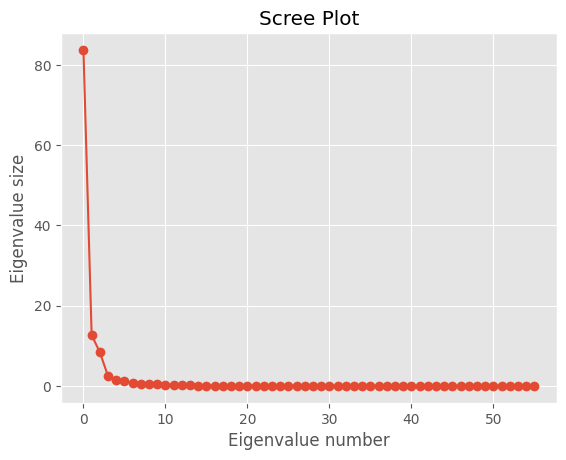

In [6]:
import matplotlib.pyplot as plt
plt.style.use("ggplot") 
plt.plot(pca.explained_variance_, marker='o')
plt.xlabel("Eigenvalue number")
plt.ylabel("Eigenvalue size")
plt.title("Scree Plot")

In [7]:
cumvar = np.cumsum(pca.explained_variance_ratio_)
n_components = np.argmax(cumvar >= 0.99) + 1
print(f"Components for 99% variance: {n_components}")

Components for 99% variance: 11


In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score

pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)

K_RANGE = range(2, 16)
inertias, sil_scores, db_scores = [], [], []

# Sample for silhouette speed
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X_pca), min(50000, len(X_pca)), replace=False)
X_sample = X_pca[sample_idx]

print('Test k from 2 to 16')
for k in K_RANGE:
  km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
  labels_k = km.fit_predict(X_pca)
  inertias.append(km.inertia_)
  sil_scores.append(silhouette_score(X_sample, labels_k[sample_idx]))
  db_scores.append(davies_bouldin_score(X_sample, labels_k[sample_idx]))
  print(f'k={k:2d}  inertia={km.inertia_:,.0f} sil={sil_scores[-1]:.4f}  db={db_scores[-1]:.4f}')

Test k from 2 to 16
k= 2  inertia=10,597,373 sil=0.7510  db=0.4015
k= 3  inertia=6,673,577 sil=0.7267  db=0.4782
k= 4  inertia=3,531,325 sil=0.8214  db=0.5176
k= 5  inertia=2,892,425 sil=0.8320  db=0.6118
k= 6  inertia=2,344,342 sil=0.8235  db=0.7677
k= 7  inertia=1,921,173 sil=0.8385  db=0.6810
k= 8  inertia=1,489,009 sil=0.8460  db=0.6322
k= 9  inertia=1,270,423 sil=0.8509  db=0.6461
k=10  inertia=1,112,216 sil=0.8181  db=0.6843
k=11  inertia=972,820 sil=0.8236  db=0.6821
k=12  inertia=888,134 sil=0.8270  db=0.6457
k=13  inertia=791,671 sil=0.8381  db=0.6254
k=14  inertia=707,412 sil=0.8246  db=0.6418
k=15  inertia=669,468 sil=0.8282  db=0.6425


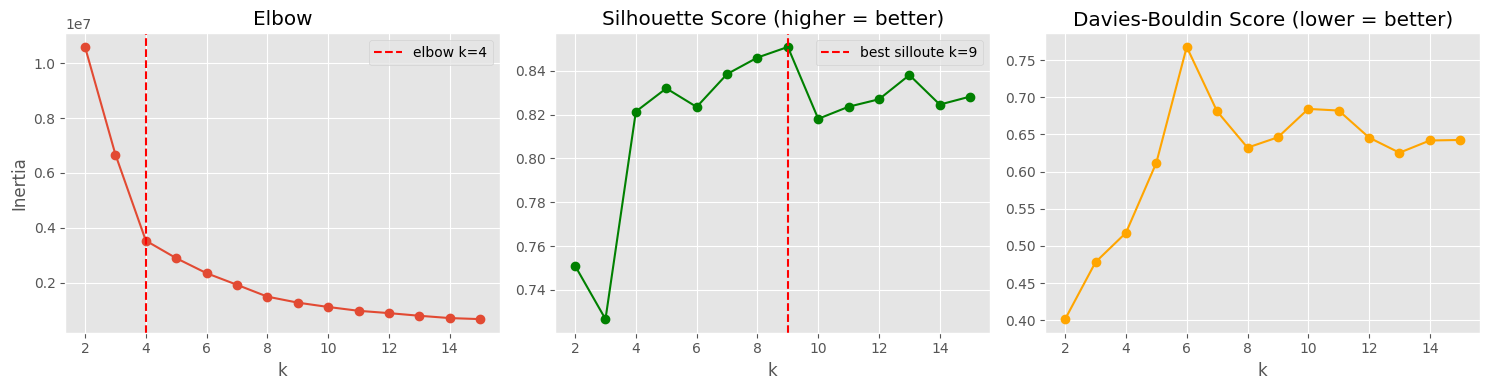

Elbow method suggests k=4
Best silhouette suggests k=9


In [9]:
import matplotlib.pyplot as plt
from kneed import KneeLocator
import os

kneedle = KneeLocator(list(K_RANGE), inertias, curve='convex', direction='decreasing')
k_elbow = kneedle.knee or int(np.argmax(sil_scores)) + 2
k_silloute = int(np.argmax(sil_scores)) + 2

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(list(K_RANGE), inertias, marker='o')
axes[0].axvline(k_elbow, color='red', linestyle='--', label=f'elbow k={k_elbow}')
axes[0].set_title('Elbow')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')
axes[0].legend()

axes[1].plot(list(K_RANGE), sil_scores, marker='o', color='green')
axes[1].axvline(k_silloute, color='red', linestyle='--', label=f'best silloute k={k_silloute}')
axes[1].set_title('Silhouette Score (higher = better)')
axes[1].set_xlabel('k')
axes[1].legend()

axes[2].plot(list(K_RANGE), db_scores, marker='o', color='orange')
axes[2].set_title('Davies-Bouldin Score (lower = better)')
axes[2].set_xlabel('k')

os.makedirs('figures/22_kmeans', exist_ok=True)

plt.tight_layout()
plt.savefig('figures/22_kmeans/kmeans_elbow_sil.png', dpi=150)
plt.show()

print(f'Elbow method suggests k={k_elbow}')
print(f'Best silhouette suggests k={k_silloute}')

### Final K-means fit
Set K_FINAL based on the plots above. Default is the elbow value.

In [10]:
K_FINAL = 5

print(f'K-means with k={K_FINAL}')
km_final = KMeans(n_clusters=K_FINAL, init='k-means++', n_init=20, random_state=42)
km_final.fit(X_pca)
labels = km_final.labels_

print(f'Inertia: {km_final.inertia_:,.0f}')
print(f'Silhouette: {silhouette_score(X_sample, labels[sample_idx]):.4f}')
print(f'Davies-Bouldin: {davies_bouldin_score(X_sample, labels[sample_idx]):.4f}')

unique, counts = np.unique(labels, return_counts=True)
for cl, ct in zip(unique, counts):
  print(f'Cluster {cl}: {ct:,} flows ({ct/len(labels)*100:.1f}%)')

K-means with k=5
Inertia: 2,892,425
Silhouette: 0.8320
Davies-Bouldin: 0.6118
Cluster 0: 169,246 flows (53.3%)
Cluster 1: 54,428 flows (17.1%)
Cluster 2: 9,846 flows (3.1%)
Cluster 3: 71,569 flows (22.5%)
Cluster 4: 12,576 flows (4.0%)


### Overiview of how each feature impacts each cluster

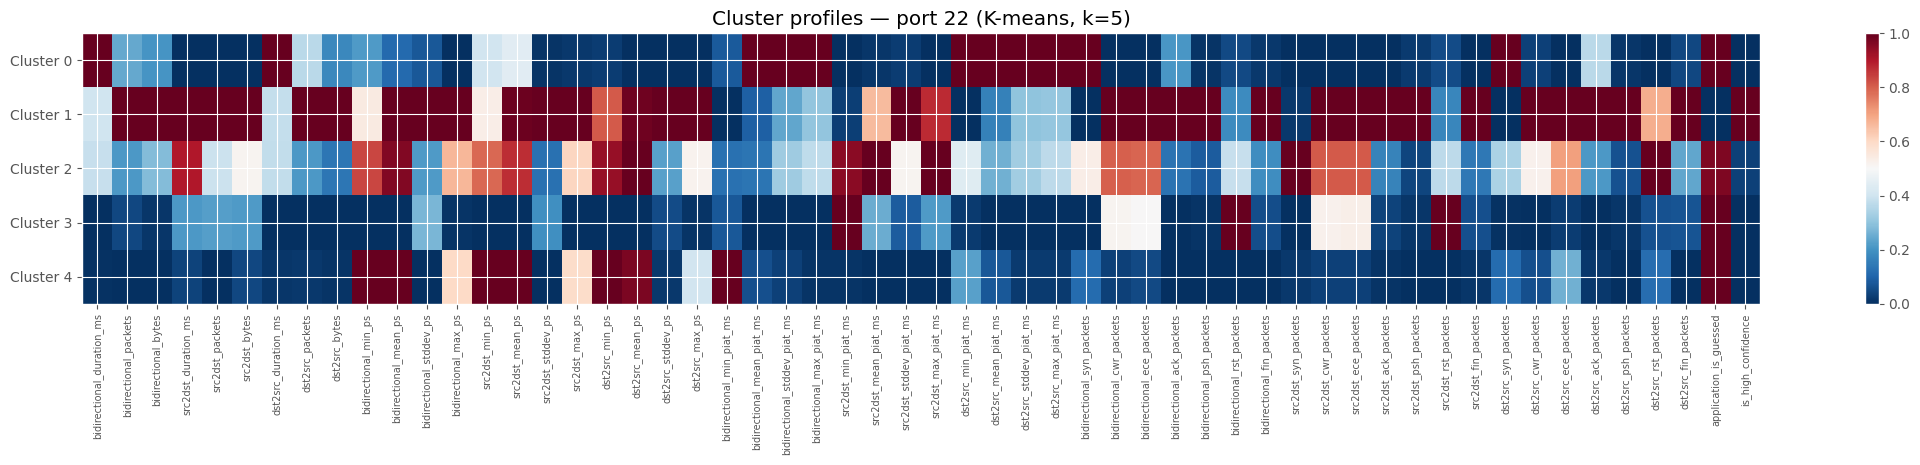

In [11]:
feature_names = df.columns

# Convert K-means centers from PCA space -> scaled feature space -> original feature space
centers_original = scaler.inverse_transform(pca.inverse_transform(km_final.cluster_centers_))

centroids_df = pd.DataFrame(centers_original, columns=feature_names)

# Normalise to [0,1] per feature for visual clarity
norm = (centroids_df - centroids_df.min()) / (centroids_df.max() - centroids_df.min() + 1e-9)

fig_w = max(22, len(feature_names) * 0.28)
fig_h = max(4, K_FINAL * 0.55 + 2)

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
im = ax.imshow(norm.values, aspect='auto', cmap='RdBu_r', vmin=0, vmax=1)

ax.set_xticks(range(len(feature_names)))
ax.set_xticklabels(feature_names, rotation=90, fontsize=7)
ax.set_yticks(range(K_FINAL))
ax.set_yticklabels([f'Cluster {i}' for i in range(K_FINAL)])
ax.set_title(f'Cluster profiles — port 22 (K-means, k={K_FINAL})')

plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig('figures/22_kmeans/kmeans_heatmap.png', dpi=150)
plt.show()

### UMAP projection with k = 5

/Users/jesusbeneytogomez-polo/Desktop/thesis/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


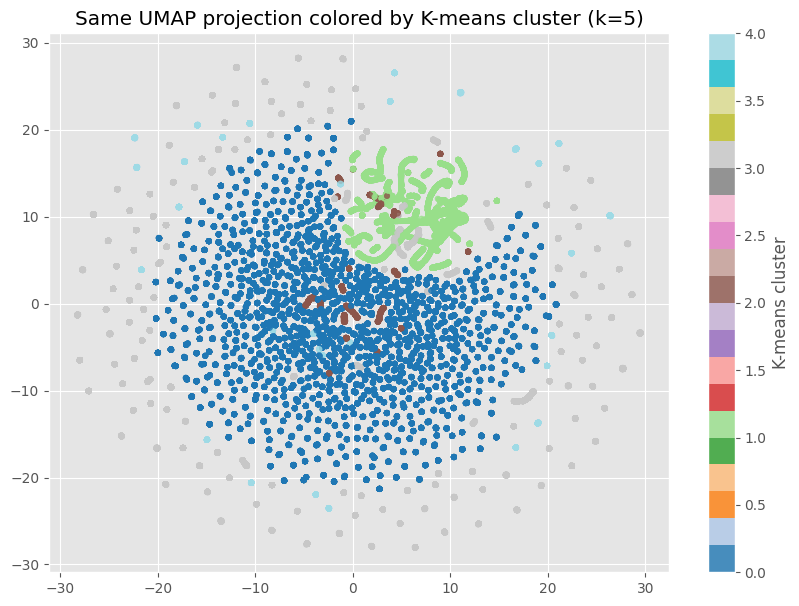

Saved figures/22_kmeans/kmeans_umap.png


In [12]:
import umap

reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=42)
# projection = reducer.fit_transform(X_pca)

viz_idx = rng.choice(len(X_pca), min(50000, len(X_pca)), replace=False)
X_viz = X_pca[viz_idx]
labels_viz = labels[viz_idx]
projection = reducer.fit_transform(X_viz)

cmap_30 = plt.get_cmap('viridis').resampled(4)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(projection[:, 0],projection[:, 1],c=labels_viz,cmap='tab20',s=15,alpha=0.8)
plt.colorbar(scatter, label='K-means cluster')
plt.title(f"Same UMAP projection colored by K-means cluster (k={K_FINAL})")
plt.savefig('figures/22_kmeans/kmeans_umap.png', dpi=150)
plt.show()
print('Saved figures/22_kmeans/kmeans_umap.png')

#### Overview (Check clusters/clusters_22_kmeans better)

In [13]:
import ast

df_full = pd.read_csv("results/sorted_enriched_port_22.csv", low_memory=False)
df_full["cluster"] = labels

stat_cols = [
  'bidirectional_packets', 'bidirectional_bytes', 'bidirectional_duration_ms',
  'bidirectional_syn_packets', 'bidirectional_rst_packets', 'bidirectional_fin_packets'
]

for c in sorted(df_full["cluster"].unique()):
  subset = df_full[df_full["cluster"] == c]
  stats = subset[stat_cols].mean().round(1)

  # Did the SSH handshake complete
  handshake_rate = subset['clients'].notna().mean()

  # Authentication outcome
  auth = subset['auth_success'].dropna().value_counts().to_dict()

  # Client banner 
  clients = []
  for v in subset['clients'].dropna():
    try: clients.extend(ast.literal_eval(v))
    except: pass
  clients = pd.Series(clients).value_counts().to_dict() if clients else {}

  print(f"\nCluster {c} ({len(subset)} flows")
  print(f"pkts={stats['bidirectional_packets']} "
    f"bytes={stats['bidirectional_bytes']} "
    f"dur={stats['bidirectional_duration_ms']}ms "
    f"syn={stats['bidirectional_syn_packets']} "
    f"rst={stats['bidirectional_rst_packets']} "
    f"fin={stats['bidirectional_fin_packets']} "
    f"handshake_rate: {handshake_rate} ")
  if auth: print(f"auth_success: {auth} ")
  if clients: print(f"clients: {clients}")


Cluster 0 (169246 flows
pkts=7.0 bytes=409.5 dur=31698.9ms syn=7.0 rst=0.0 fin=0.0 handshake_rate: 5.90855913876842e-06 
auth_success: {'unknown': 1} 

Cluster 1 (54428 flows
pkts=55.8 bytes=27821.0 dur=12747.8ms syn=2.1 rst=0.2 fin=2.0 handshake_rate: 0.985871242742706 
auth_success: {'success': 27558, 'unknown': 25662, 'failed': 439} 
clients: {'SSH-2.0-Go': 30347, 'SSH-2.0-libssh_0.11.1': 11291, 'SSH-2.0-PUTTY': 4605, 'SSH-2.0-PuTTY_Release_0.80': 1706, 'SSH-2.0-libssh2_1.9.0': 1330, 'SSH-2.0-AsyncSSH_2.1.0': 430, 'SSH-2.0-OpenSSH_8.4p1 Debian-5+deb11u3': 289, 'SSH-2.0-OpenSSH_8.9p19': 277, 'SSH-2.0-libssh_0.9.6': 248, 'SSH-2.0-OPENSSH_7.9': 246, 'SSH-2.0-ZGrab ZGrab SSH Survey': 187, 'SSH-2.0-paramiko_4.0.0': 96, 'SSH-2.0-libssh2_1.11.0': 90, 'SSH-2.0-libssh_0.7.4': 80, 'SSH-2.0-paramiko_3.4.0': 80, 'SSH-2.0-libssh_0.10.5': 73, 'SSH-2.0-libssh2_1.11.1': 70, 'SSH-2.0-OpenSSH-keyscan': 70, 'SSH-2.0-OpenSSH_9.2p1 Debian-2+deb12u6': 65, 'SSH-2.0-OpenSSH_9.2p1 Debian-2+deb12u7': 50, 'S

In [23]:
from sklearn.metrics.pairwise import euclidean_distances
import numpy as np
import os
import pandas as pd

df_full = pd.read_csv("results/sorted_enriched_port_22.csv", low_memory=False)

df_full["cluster"] = labels

os.makedirs("clusters/clusters_22_kmeans", exist_ok=True)

cluster_sizes = df_full["cluster"].value_counts().to_dict()

centroids_scaled = km_final.cluster_centers_

for cluster_id in sorted(df_full["cluster"].unique()):
  subset_idx = df_full.index[df_full["cluster"] == cluster_id].to_numpy()
  subset_scaled = X_pca[subset_idx]
  dists = euclidean_distances( subset_scaled, centroids_scaled[cluster_id].reshape(1, -1)).flatten()
  
  # Store distance to centroid so we can sort like in the HDBSCAN version
  df_full.loc[subset_idx, "distance_to_centroid"] = dists
  # Most representative: closest to centroid
  representative_idx = (df_full.loc[subset_idx].sort_values("distance_to_centroid", ascending=True).head(200).index)
  # Most anomalous: furthest from centroid
  anomalous_idx = (df_full.loc[subset_idx].sort_values("distance_to_centroid", ascending=False).head(200).index)

  df_full.loc[representative_idx].to_csv(f"clusters/clusters_22_kmeans/{cluster_id:02d}_representative.csv",index=False)
  df_full.loc[anomalous_idx].to_csv(f"clusters/clusters_22_kmeans/{cluster_id:02d}_anomalous.csv",index=False)
  print(f"Saved cluster {cluster_id} ({cluster_sizes[cluster_id]} flows)")

Saved cluster 0 (169246 flows)
Saved cluster 1 (54428 flows)
Saved cluster 2 (9846 flows)
Saved cluster 3 (71569 flows)
Saved cluster 4 (12576 flows)
